# Taller 2 — Aprendizaje profundo para procesamiento de imágenes

**Asignatura:** TEL328 - PROCESAMIENTO DIGITAL DE IMÁGENES

**Publicación:** viernes 23 de octubre de 2026, 00:00  
**Fecha límite:** domingo 1 de noviembre de 2026, 23:59  
**Modalidad:** individual  
**Entrega:** un único ZIP en Aula USM  
**Nombre del archivo:** `Taller_2_Nombre_Apellido.zip`

**Nombre:** Ignacio   
**Apellido:** Figueroa

## Objetivo

Cada estudiante definirá un problema propio de reconocimiento visual, construirá un conjunto de datos, anotará imágenes en **Roboflow**, entrenará un detector de objetos basado en **YOLO** y evaluará sus resultados. Además, entrenará un modelo de **clasificación de imágenes** y comparará ambas tareas.

El objetivo no es implementar redes neuronales desde cero, sino utilizar herramientas existentes correctamente, diseñar experimentos, interpretar métricas y analizar limitaciones. No se exige alcanzar una precisión mínima arbitraria: se evaluará la calidad del procedimiento, la evaluación, el análisis y la reproducibilidad.

## 1. Fechas, modalidad y entrega

- Publicación: **viernes 23 de octubre de 2026 a las 00:00**.
- Fecha límite: **domingo 1 de noviembre de 2026 a las 23:59**.
- Trabajo **individual**.
- Suba a **Aula USM un único archivo ZIP** llamado `Taller_2_Nombre_Apellido.zip`.

El ZIP debe contener:
1. Este notebook completado (`.ipynb`), con código, resultados y respuestas.
2. Un `README.md` **o** un informe breve en PDF.
3. En el README/informe, el enlace al proyecto de Roboflow y a la versión exacta del dataset utilizada.

**No suba imágenes ni el dataset a Aula USM.** Manténgalos alojados en Roboflow para evitar sobrecargar la plataforma. Verifique que el repo sea de libre acceso para que los ayudantes puedan revisarlo.

## 2. Reglas generales

1. El trabajo es individual; cada estudiante debe elegir su problema y construir su dataset.
2. Se permite consultar documentación y usar IA como apoyo, pero usted debe comprender el código, justificar decisiones y explicar resultados.
3. No necesita implementar desde cero YOLO, redes neuronales ni métricas disponibles en librerías.
4. Las decisiones relevantes deben justificarse en celdas Markdown. No basta con ejecutar código o mostrar métricas.
5. Los resultados deben provenir de la ejecución real del código; no se aceptan resultados inventados ni figuras pegadas sin el código que las genera.
6. Declare el código externo o asistencia de IA sustantiva que utilizó. Usted es responsable de verificarlo.
7. Registre las versiones de librerías, entorno y configuración de experimentos.
8. Se podrá solicitar una explicación breve del notebook, los datos o los resultados.
9. No exponga claves API, tokens ni contraseñas en el notebook entregado.

## 3. Problema y conjunto de datos

Elija **tres clases** de objetos visualmente distinguibles y con suficientes imágenes disponibles. Ejemplos orientativos: tipos de hojas, frutas, señales, herramientas, envases, vehículos, animales comunes u objetos de escritorio. Elija un tema propio.

**Clase 1:** Auto
**Clase 2:** Motocicleta
**Clase 3:** Bicicleta

**Problema que desea resolver:** Desarrolar un sistema de visión artificial capaz de detectar y clasificar tres tipos de vehículos: autos, motocicletas y bicicletas, a partir de imágenes. Se busca que el modelo pueda reconocer estos vehículos y, en el caso de la detección de objetos, identificar su ubicación dentro de la imagen mediante cuadros delimitadores

**¿Por qué estas clases son interesantes y distinguibles visualmente?**  

Porque correspondern a medios de transporte comunes que podemos encontrar en entornos urbanos. Además, presentan características visuales que permiten diferenciarlas, como su tamaño, estructura y cantidad de ruedas. Los autos poseen una carrocería cerrada, mientras que las motocicletas y bicicletas tienen estructuras mas pequeñas y abiertas. Estas últimas comparten ciertas similitudes,lo que representa un desafío interesante para el modelo al momento de distinguirlas.

**¿En qué situaciones podría fallar el sistema?**  

Se podría presentar dificultades cuando los vehículos aparecen parcialmente ocultos, están muy alejados de la cámara o las imágenes tienen poca iluminación o baja resolución. También podría confundir motocicletas con bicicletas debido a sus similitudes visuales, especialmente si se observan desde ciertos ángulos. Otro posible problema sería detectar vehículos en entornos o condiciones muy diferentes a las imágenes utilizadas drante el entrenamiento
### Requisitos mínimos

- Al menos **120 imágenes en total** y **40 por clase**.
- Puede usar fotografías propias, imágenes de Internet o una combinación. Tomar fotos propias es opcional.
- Documente las fuentes mediante enlaces o referencias y respete licencias y condiciones de uso.
- Busque variedad de fondos, iluminación, tamaños y perspectivas. Evite que el modelo pueda reconocer una clase solo por su fondo o marca de agua.
- Quite duplicados y evite imágenes casi idénticas en entrenamiento y evaluación.
- Las imágenes de prueba deben ser independientes de las usadas para entrenar o ajustar el modelo.
- La selección, revisión, organización y documentación de datos deben ser realizadas por usted.

Explique cómo reunió las imágenes, qué fuentes usó y cómo buscó diversidad y evitó duplicados.

## 4. Entorno de ejecución

Puede trabajar en **Google Colab** o en un equipo local.

- **Colab** es recomendable si no dispone de GPU compatible. Revise la disponibilidad del acelerador y guarde resultados importantes en almacenamiento persistente: la sesión puede desconectarse.
- **Local** es válido si cuenta con recursos suficientes. Documente el hardware y las versiones del software.

No se calificará mejor a quien tenga una GPU más potente. Se evaluará el diseño experimental y el análisis honesto.

In [ ]:
import os, sys, platform, time
from datetime import datetime

print("Python:", sys.version)
print("Plataforma:", platform.platform())
print("Fecha/hora:", datetime.now().isoformat(timespec="seconds"))
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA disponible:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch todavía no está instalado.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Plataforma: Linux-6.6.159+-x86_64-with-glibc2.39
Fecha/hora: 2026-11-01T02:56:27
PyTorch: 2.11.0+cu130
CUDA disponible: True
GPU: Tesla T4


**Entorno usado (Colab/local):** Google colab

**GPU/CPU disponible:** GPU NVIDIA Tesla T4

**Limitaciones relevantes:** La disponibilidad de GPU en Google Colab depende de los recursos asignados

---

## 5. Roboflow: creación y anotación del dataset de detección

Use [Roboflow](https://roboflow.com/) para organizar y anotar las imágenes.

1. Cree un proyecto de tipo **Object Detection**.
2. Cargue las imágenes y defina sus tres clases.
3. Dibuje una caja delimitadora (*bounding box*) alrededor de cada instancia visible de las clases objetivo. Si una imagen contiene varios objetos relevantes, anote cada uno.
4. Revise las cajas y etiquetas para detectar omisiones, cajas mal ajustadas o etiquetas incorrectas.
5. Genere una versión del dataset y defina particiones de entrenamiento, validación y prueba.
6. Como referencia, puede usar 70 % entrenamiento, 15 % validación y 15 % prueba; justifique otra distribución si la usa.
7. Evite imágenes duplicadas o casi idénticas en particiones distintas. No use el conjunto de prueba para elegir hiperparámetros.

### Resumen del dataset

| Elemento | Información |
|---|---|
| Nombre del proyecto de Roboflow | Detección de vehículos|
| Enlace al proyecto |https://app.roboflow.com/ignacios-workspace-z5vta/deteccion-de-vehiculos-j8kzu/1|
| Enlace/identificador de la versión utilizada |Versión 1 v1 |
| Número total de imágenes | 122 imágenes|
| Imágenes por clase | 64 autos, 41 motos, 41 bicicletas. Algunas fotografías contienen objetos de más de una clase, por lo que se cuenta en cada clase correspondiente|
| Distribución train / validation / test | 85/18/19 imágenes|
| Número aproximado de objetos anotados |502 (303 autos, 124 motocicletas, 75 bicicletas) |
| Fuentes de imágenes |https://www.pexels.com/es-es/  ; https://unsplash.com/es |
| ¿Cómo revisó la calidad de las anotaciones? | Se revisaron visualmente las cajas delimitadoras y las etiquetas, corrigiendo aquellas mal ajustadas o incorrectas y comprobando que los vehículos relevantes estuvieran anotados.|

### Revisión crítica

1. ¿Qué criterios usó para seleccionar imágenes?

**Respuesta** : Se seleccionaron imágenes de autos, motocicletas y bicicletas buscando variedad en los modelos, ángulos de visión, fondos y condiciones de iluminación. Se priorizaron fotografías donde los vehículos fueran reconocibles, incluyendo imágenes con uno o varios objetos, para que el modelo pudiera aprender a identificarlos en diferentes situaciones.

2. ¿Qué casos fueron difíciles de anotar?

**Respuesta**: Los casos más difíciles fueron las imágenes con varios vehículos, especialmente cuando aparecían muy pequeños, parcialmente ocultos o borrosos. En estas situaciones resultaba más complicado ajustar correctamente las cajas delimitadoras y decidir qué objetos podían identificarse con suficiente claridad. También fue necesario revisar algunas detecciones automáticas para evitar cajas innecesarias o mal ubicadas.

3. ¿Qué clases o condiciones están subrepresentadas?

**Respuesta**: Se intentó mantener una cantidad similar de imágenes para las tres clases. Sin embargo, la cantidad de objetos anotados por clase puede variar, debido a que algunas fotografías contienen varios vehículos.

4. ¿Cómo comprobó que no hubiera duplicados entre particiones?

**Respuesta**: Se consideró la necesidad de evitar imágenes duplicadas o casi idénticas entre los conjuntos de entrenamiento, validación y prueba, ya que podrían producir una evaluación poco representativa. Se compararon las imágenes de entrenamiento, validación y prueba en los datasets de detección y clasificación. En ambos casos se obtuvieron 0 duplicados exactos y 0 coincidencias entre particiones, por lo que no se encontraron evidencias de fuga de datos por archivos idénticos.

5. ¿Qué sesgos podría contener el dataset?

**Respuesta**: El dataset podría presentar sesgos relacionados con el tipo de fotografías seleccionadas, ya que muchas provienen de bancos de imágenes y muestran vehículos en buenas condiciones de iluminación o desde ángulos favorables. También puede existir una mayor representación de ciertos modelos de vehículos y entornos urbanos. Esto podría provocar que el modelo tenga mayores dificultades al detectar vehículos en condiciones diferentes a las utilizadas durante el entrenamiento.

## 6. Detección de objetos con YOLO

Entrenará un modelo YOLO preentrenado mediante **transfer learning** (transferencia de aprendizaje): se parte de pesos que ya aprendieron características visuales y se ajustan a sus clases.

Consulte la [documentación de Ultralytics YOLO](https://docs.ultralytics.com/) y la [documentación de Roboflow](https://docs.roboflow.com/). No copie una receta sin comprenderla. Descargue desde Roboflow una versión compatible con Ultralytics y localice el archivo `data.yaml`.

**Ruta a `data.yaml`:**  /content/Detección-de-vehiculos-1/data.yaml

**Formato de exportación:** YOLOv8

**¿Cómo verificó las clases y las particiones?:** Se comprobó mediante Python que el archivo data.yaml existe y contiene las tres clases definidas: auto, bicicleta y motocicleta. También se verificó que incluye las rutas de entrenamiento, validación y prueba. Según la configuración de Roboflow, las 122 imágenes están distribuidas en 85 de entrenamiento, 18 de validación y 19 de prueba, aproximadamente en proporción 70/15/15.

No escriba su clave API en una celda que luego compartirá. Si utiliza la API de Roboflow, introduzca la clave de forma privada en el entorno.

In [ ]:
# En Colab, si es necesario, instale las librerías:
%pip install -q ultralytics roboflow

import ultralytics
print("Ultralytics:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.197


In [ ]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
project = rf.workspace("ignacios-workspace-z5vta").project("deteccion-de-vehiculos-j8kzu")
version = project.version(1)

dataset = version.download("yolov8")

print("Dataset descargado en:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Detección-de-vehiculos-1 in yolov8:: 100%|██████████| 249/249 [00:00<00:00, 8292.69it/s]

Dataset descargado en: /content/Detección-de-vehiculos-1


In [ ]:
from pathlib import Path
import yaml
DATA_YAML = str(Path(dataset.location)/ "data.yaml")
print("Ruta:", DATA_YAML)
print("¿Existe?:", Path(DATA_YAML).exists())
if Path(DATA_YAML).exists():
    with open(DATA_YAML, "r") as f:
        config = yaml.safe_load(f)

    print("Clases:", config["names"])
    print("Train:", config["train"])
    print("Valid:", config["val"])
    print("Test:", config["test"])

Ruta: /content/Detección-de-vehiculos-1/data.yaml
¿Existe?: True
Clases: ['auto', 'bicicleta', 'motocicleta']
Train: ../train/images
Valid: ../valid/images
Test: ../test/images


### 6.1. Experimento de referencia

Elija un modelo pequeño preentrenado. Ajuste la ruta y los parámetros a su entorno. Si el lote no cabe en la memoria disponible, redúzcalo y documente el cambio.

In [ ]:
from ultralytics import YOLO

DATA_YAML = "/content/Detección-de-vehiculos-1/data.yaml"  # Actualice esta ruta
MODEL_NAME = "yolo11n.pt"

assert os.path.exists(DATA_YAML), "Actualice DATA_YAML a la ruta real del archivo data.yaml"

model = YOLO(MODEL_NAME)
start = time.time()
results = model.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=16,
    patience=8,
    plots=True,
    project="runs_taller2",
    name="yolo_experimento_1"
)
print(f"Tiempo de entrenamiento: {(time.time()-start)/60:.1f} minutos")

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Detección-de-vehiculos-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_experimento_1, nbs=64, nms=None, opset=No

En el primer experimento se entrenó el modelo YOLO11n utilizando 122 imágenes distribuidas en entrenamiento, validación y prueba. Se configuraron 30 épocas, un tamaño de imagen de 640 píxeles, batch de 16 y patience de 8.

El entrenamiento finalizó anticipadamente después de 9 épocas debido a Early Stopping. Se obtuvo una precision global de 0,206, recall de 0,162, mAP@50 de 0,168 y mAP@50:95 de 0,134 en el conjunto de validación.

La clase auto presentó el mejor desempeño, con un mAP@50 de 0,497, mientras que bicicleta y motocicleta obtuvieron resultados cercanos a cero. Esto indica que el modelo todavía presenta dificultades para generalizar correctamente a las tres clases. Una posible causa es la baja cantidad de ejemplos de bicicletas y motocicletas en validación, junto con el tamaño reducido del dataset.

### 6.2. Experimentos controlados

Realice **al menos dos experimentos de detección**. El primero será su referencia; en el segundo cambie al menos un parámetro relevante (por ejemplo, épocas, tamaño de imagen o estrategia de entrenamiento), manteniendo los demás constantes en lo posible. El segundo experimento no tiene que ser mejor.

| Experimento | Modelo | Épocas | Tamaño de imagen | Batch | Otro cambio |
|---|---|---:|---:|---:|---|
| 1 | YOLO11n| 30| 640| 16| patience=8|
| 2 | YOLO11n| 30| 640| 16| patience=20|

**Hipótesis para el experimento 2:** Al aumentar el parámetro patience de 8 a 20, se espera que el modelo pueda entrenar durante más épocas antes de detenerse anticipadamente, lo que podría permitir una mejora en las métricas de detección, especialmente en las clases bicicleta y motocicleta.

**¿Por qué eligió ese parámetro?:** Se eligió modificar patience porque en el primer experimento el entrenamiento se detuvo en la época 9, sin completar las 30 épocas configuradas. Al aumentar este valor, se busca comprobar si permitir más épocas sin mejoras consecutivas ayuda al modelo a obtener un mejor rendimiento.

Use un nombre distinto para guardar la segunda ejecución y no sobrescriba la primera.

In [ ]:
model2 = YOLO(MODEL_NAME)

start2 = time.time()

results2 = model2.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=16,
    patience=20,
    plots=True,
    project="runs_taller2",
    name="yolo_experimento_2"
)

print(f"Tiempo de entrenamiento: {(time.time()-start2)/60:.1f} minutos")

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Detección-de-vehiculos-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_experimento_2, nbs=64, nms=None, opset=No

En el segundo experimento se mantuvo el modelo YOLO11n y los parámetros del primer entrenamiento, modificando únicamente el valor de `patience` de 8 a 20. El objetivo fue permitir que el modelo continuara entrenándose durante más épocas antes de detenerse por falta de mejoras.

A diferencia del primer experimento, que finalizó anticipadamente en la época 9, el segundo completó las 30 épocas configuradas. Se obtuvieron mejores resultados en validación, con una precision de 0,664, recall de 0,739, mAP@50 de 0,727 y mAP@50:95 de 0,462.

La mejora fue especialmente notoria en las clases bicicleta y motocicleta, que anteriormente presentaban métricas cercanas a cero. Estos resultados respaldan la hipótesis de que aumentar la paciencia podía favorecer el entrenamiento, aunque no garantizan que este comportamiento se repita con otros datos o ejecuciones.

### 6.3. Evaluación del detector

Evalúe el modelo seleccionado en el conjunto de prueba una vez que haya fijado la configuración. Adapte la sintaxis si su versión de la librería lo requiere y documente los cambios.

- **Precisión (*precision*):** proporción de detecciones realizadas que son correctas.
- **Exhaustividad (*recall*):** proporción de objetos reales que el modelo logra encontrar.
- **mAP (*mean Average Precision*):** medida agregada del desempeño de detección; indique la variante reportada, por ejemplo `mAP50` o `mAP50-95`.

Interprete las métricas en conjunto. Un modelo puede aumentar precisión y perder exhaustividad, o viceversa.

In [ ]:
BEST_WEIGHTS = "/content/runs/detect/runs_taller2/yolo_experimento_2/weights/best.pt"
assert os.path.exists(BEST_WEIGHTS), "Actualice BEST_WEIGHTS a la ruta real de best.pt"

detector = YOLO(BEST_WEIGHTS)
metrics = detector.val(data=DATA_YAML, split="test", plots=True)
print(metrics)

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1730.7±636.1 MB/s, size: 81.8 KB)
val: Scanning /content/Detección-de-vehiculos-1/test/labels... 19 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 19/19 1.9Kit/s 0.0s
val: New cache created: /content/Detección-de-vehiculos-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.1it/s 1.0s
                   all         19        104      0.632      0.323      0.418      0.253
                  auto         14         67      0.729      0.373      0.506       0.26
             bicicleta          7         15      0.313      0.333      0.408       0.29
           motocicleta          6         22      0.853      0.264      0.339      0.209
Speed: 5.7ms preprocess, 16.5ms inference, 0.0ms loss,

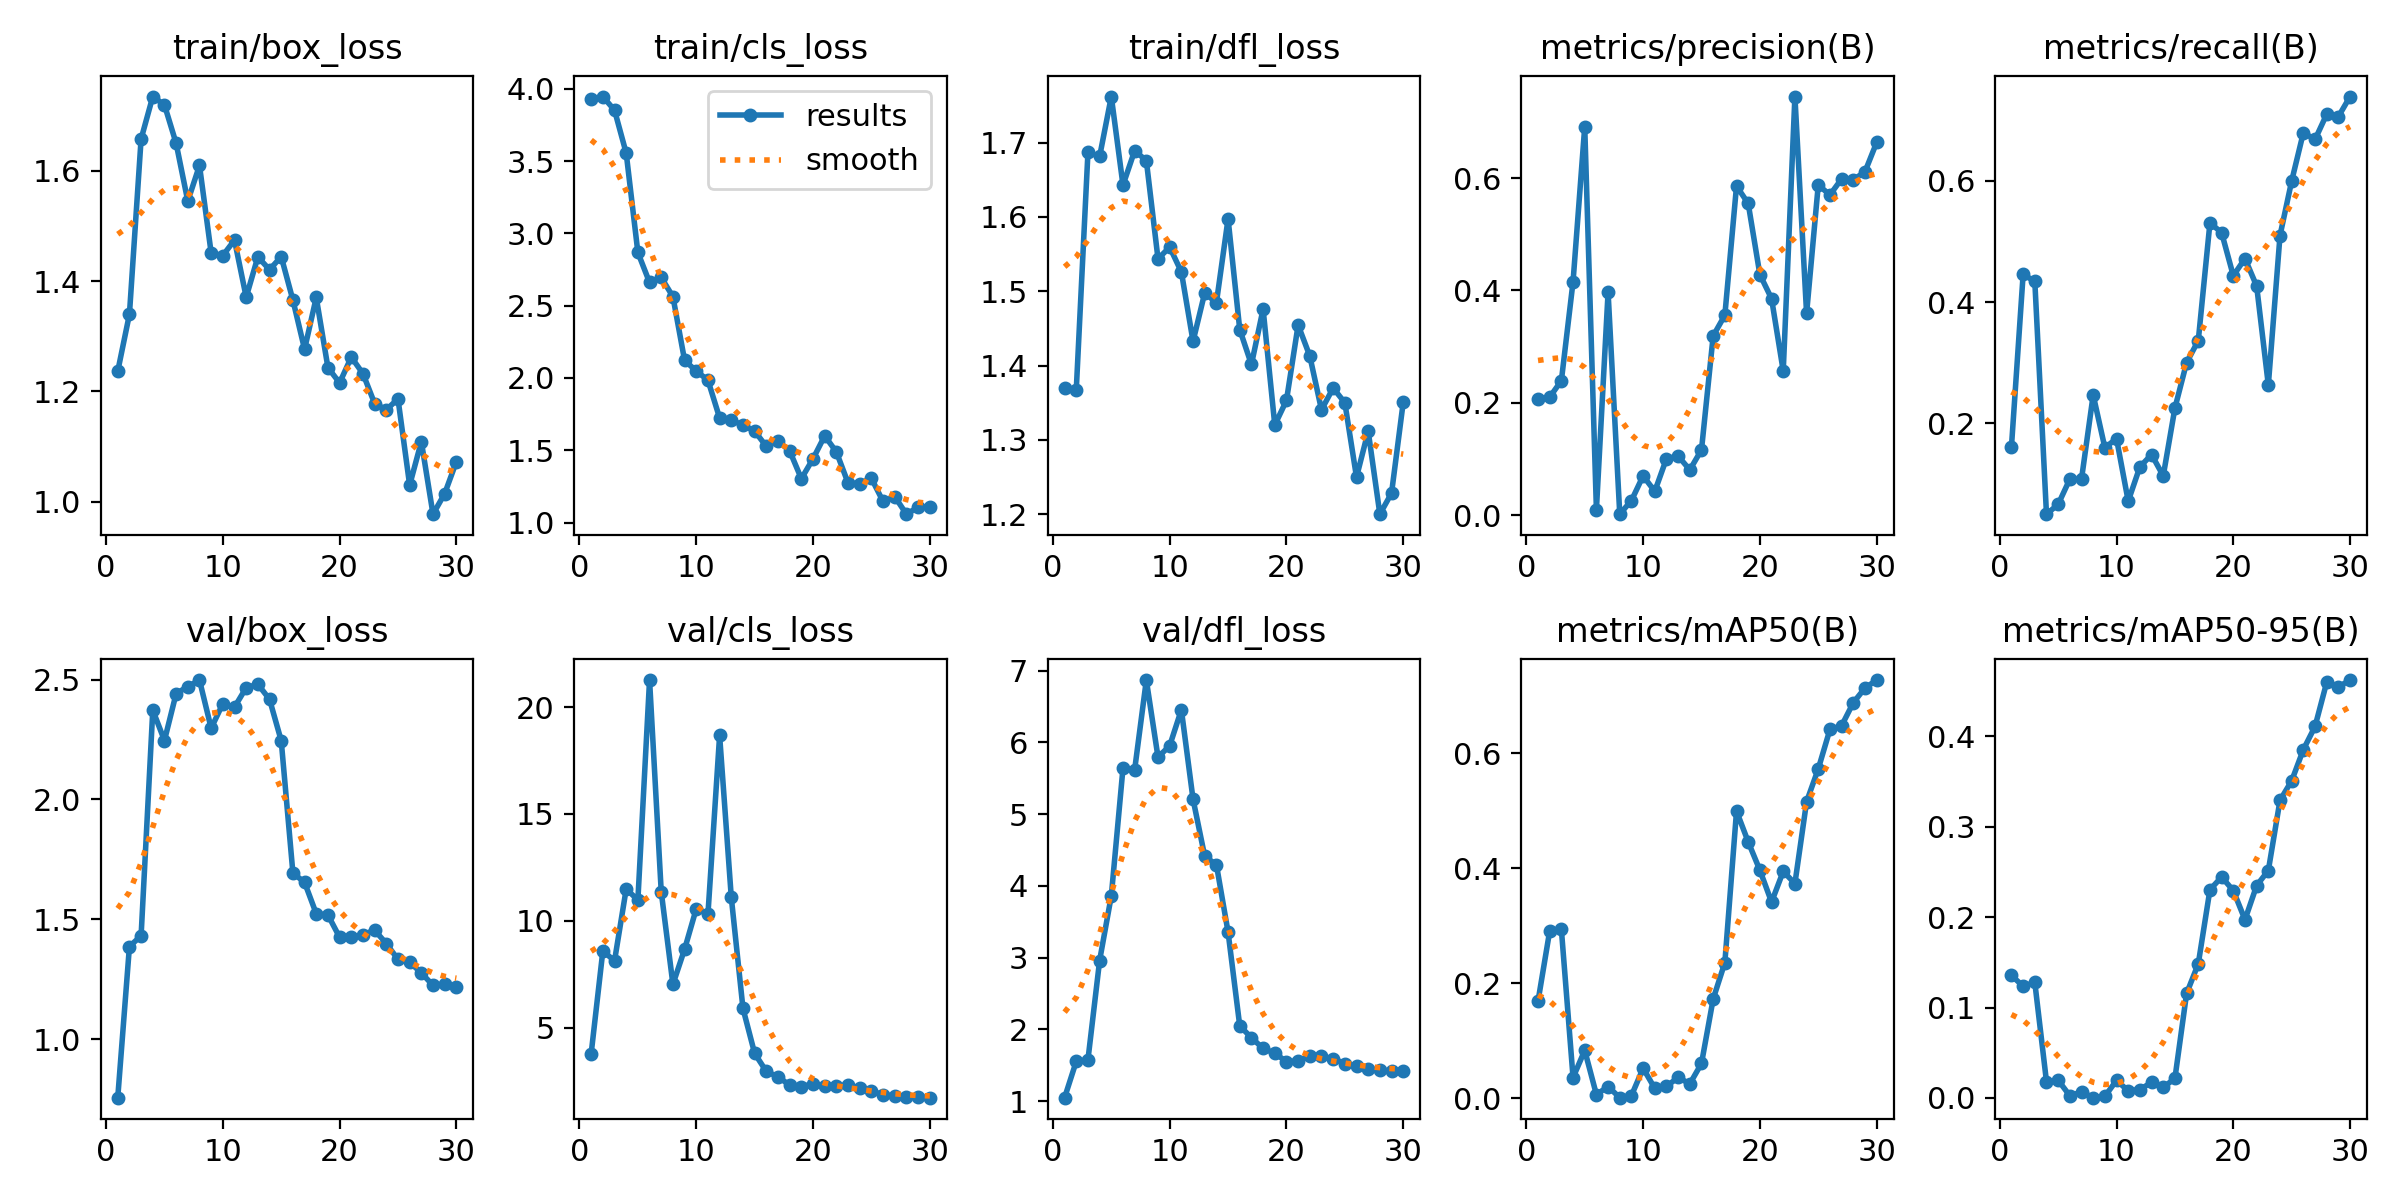

In [ ]:
from IPython.display import display, Image

ruta = "/content/runs/detect/runs_taller2/yolo_experimento_2/results.png"

display(Image(filename=ruta))

**Métricas obtenidas y modelo evaluado:**  

1. ¿Qué indican las métricas?

**Respuesta:** las métricas muestran que el modelo alcanzó una presición de 0,632, recall de 0,323, mAP@50 de 0,418 y mAP@50:95 de 0,253 en el conjunto de prueba. Esto indica que, aunque una proporción importante de sus detecciones son correctas, todavía presenta dificultades para identificar todos los vehículos presentes en las imágenes. Además, el mAP@50:95 muestra que existe margen de mejora en la localización de los objetos.

2. ¿Qué diferencias observa entre las clases?

**Respuesta:** La clase auto obtuvo el mayor mAP@50, con 0,506, seguida de bicicleta con 0,408 y motocicleta con 0,339. Las motocicletas presentaron la mayor precision (0,853), pero el menor recall (0,264), lo que significa que el modelo suele acertar cuando detecta una motocicleta, aunque deja varias sin identificar. Por otra parte, las bicicletas obtuvieron la menor precision (0,313), lo que indica una mayor presencia de detecciones incorrectas.

3. ¿Qué cambió entre experimentos y cómo explica el resultado?

**Respuesta:**Entre ambos experimentos se modificó únicamente el parámetro patience, aumentando de 8 a 20. En el primero, el entrenamiento terminó anticipadamente después de 9 épocas, mientras que el segundo completó las 30 épocas. Esto permitió que el modelo continuara aprendiendo y mejorara las métricas de validación, aumentando el mAP@50 de 0,168 a 0,727. Sin embargo, al evaluarlo sobre el conjunto de prueba, el mAP@50 disminuyó a 0,418, evidenciando dificultades para generalizar a imágenes nuevas.

4. ¿Hay indicios de sobreajuste (*overfitting*) en las curvas de entrenamiento/validación? Fundamente.

**respuesta:** Al analizar las curvas del segundo experimento, no se observa un sobreajuste evidente al final del entrenamiento, ya que tanto las pérdidas de entrenamiento como las de validación presentan una tendencia descendente. Además, las métricas mAP50 y mAP50-95 mejoran durante las últimas épocas, indicando que el modelo continúa aprendiendo.

Sin embargo, al comparar validación con prueba, el mAP50 disminuye de 0,727 a 0,418 y el recall de 0,739 a 0,323. Esto sugiere dificultades de generalización a imágenes no utilizadas durante el desarrollo. Estas diferencias podrían estar relacionadas con el tamaño reducido del dataset, la distribución de las clases o la dificultad de las imágenes. Por lo tanto, aunque las curvas no muestran señales claras de sobreajuste, tampoco se puede descartar completamente.
### 6.4. Prueba con imágenes nuevas

Pruebe el detector en **al menos 10 imágenes nuevas**, que no hayan formado parte de entrenamiento, validación, selección de parámetros ni prueba original. Pueden ser fotos propias o imágenes nuevas de Internet; registre las fuentes cuando corresponda. Muestre ejemplos acertados y erróneos, no solo los mejores.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 2736_7.original.webp to 2736_7.original.webp
Saving dendoktoor-motorcycles-6965711.jpg to dendoktoor-motorcycles-6965711.jpg
Saving latif_photo88-classic-10123453.jpg to latif_photo88-classic-10123453.jpg
Saving marcimarc105-palma-de-mallorca-2900559_1920.jpg to marcimarc105-palma-de-mallorca-2900559_1920.jpg
Saving noel_bauza-oldtimer-1197800_1920.jpg to noel_bauza-oldtimer-1197800_1920.jpg
Saving pen_ash-hoi-an-8104137.jpg to pen_ash-hoi-an-8104137.jpg
Saving surprising_media-delivery-agent-7401609_1920.jpg to surprising_media-delivery-agent-7401609_1920.jpg
Saving surprising_media-people-7756030_1920.jpg to surprising_media-people-7756030_1920.jpg
Saving wal_172619-motorcycles-7995876_1920.jpg to wal_172619-motorcycles-7995876_1920.jpg
Saving zachtleven-cycling-9394894_1920.jpg to zachtleven-cycling-9394894_1920.jpg



image 1/1 /content/2736_7.original.webp: 640x640 1 auto, 1 bicicleta, 11.9ms
Speed: 2.1ms preprocess, 11.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


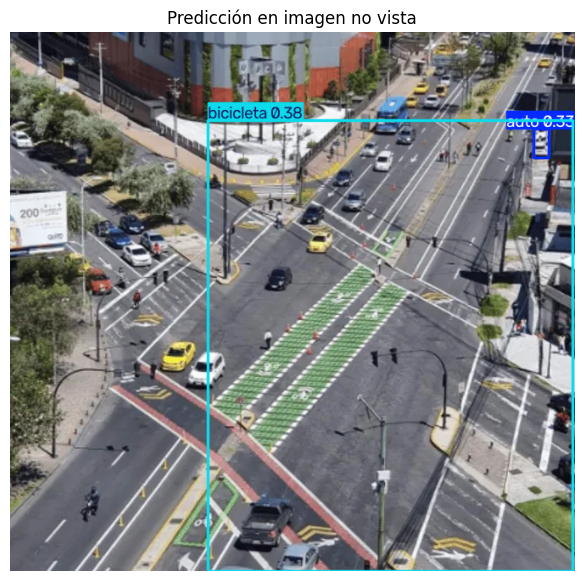

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/2736_7.original.webp"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")


image 1/1 /content/dendoktoor-motorcycles-6965711.jpg: 640x448 2 motocicletas, 10.6ms
Speed: 2.3ms preprocess, 10.6ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 448)


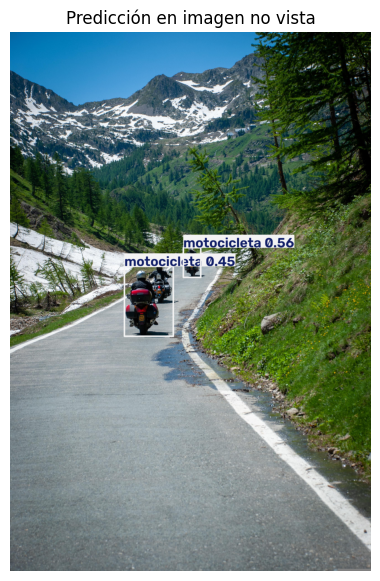

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/dendoktoor-motorcycles-6965711.jpg"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")


image 1/1 /content/latif_photo88-classic-10123453.jpg: 448x640 1 auto, 12.4ms
Speed: 2.8ms preprocess, 12.4ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)


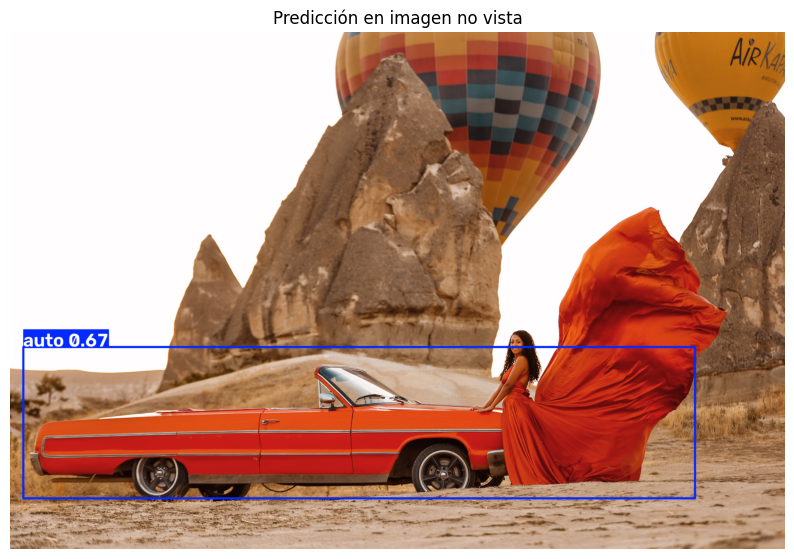

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/latif_photo88-classic-10123453.jpg"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")


image 1/1 /content/marcimarc105-palma-de-mallorca-2900559_1920.jpg: 640x448 (no detections), 10.7ms
Speed: 2.2ms preprocess, 10.7ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 448)


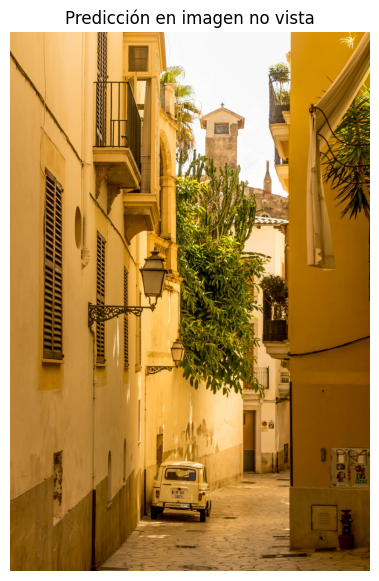

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/marcimarc105-palma-de-mallorca-2900559_1920.jpg"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")


image 1/1 /content/noel_bauza-oldtimer-1197800_1920.jpg: 448x640 1 bicicleta, 17.8ms
Speed: 2.9ms preprocess, 17.8ms inference, 2.1ms postprocess per image at shape (1, 3, 448, 640)


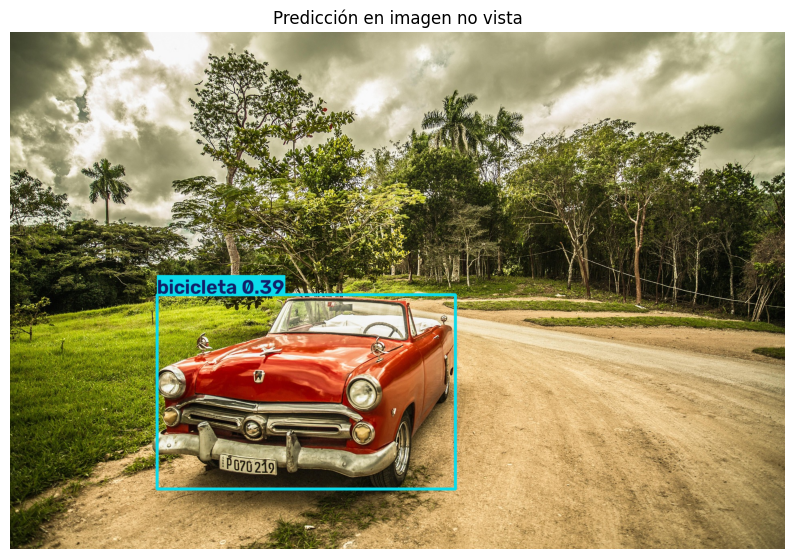

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/noel_bauza-oldtimer-1197800_1920.jpg"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")


image 1/1 /content/pen_ash-hoi-an-8104137.jpg: 640x416 (no detections), 54.8ms
Speed: 2.4ms preprocess, 54.8ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 416)


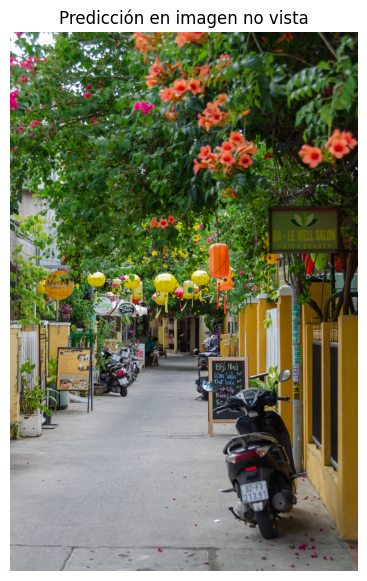

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/pen_ash-hoi-an-8104137.jpg"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")


image 1/1 /content/surprising_media-delivery-agent-7401609_1920.jpg: 640x448 3 bicicletas, 10.5ms
Speed: 2.1ms preprocess, 10.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 448)


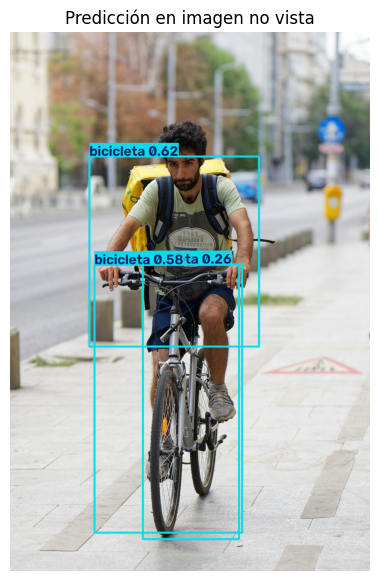

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/surprising_media-delivery-agent-7401609_1920.jpg"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")


image 1/1 /content/surprising_media-people-7756030_1920.jpg: 480x640 2 bicicletas, 1 motocicleta, 48.5ms
Speed: 2.4ms preprocess, 48.5ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)


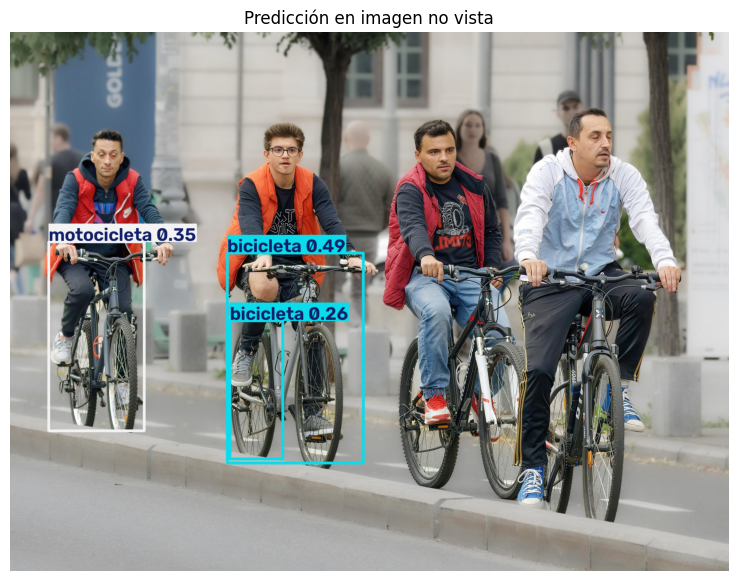

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/surprising_media-people-7756030_1920.jpg"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")


image 1/1 /content/wal_172619-motorcycles-7995876_1920.jpg: 640x448 2 autos, 3 motocicletas, 46.6ms
Speed: 2.0ms preprocess, 46.6ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 448)


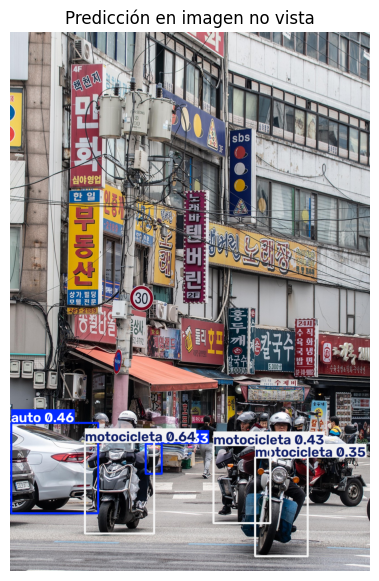

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/wal_172619-motorcycles-7995876_1920.jpg"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")


image 1/1 /content/zachtleven-cycling-9394894_1920.jpg: 448x640 (no detections), 8.1ms
Speed: 1.9ms preprocess, 8.1ms inference, 0.5ms postprocess per image at shape (1, 3, 448, 640)


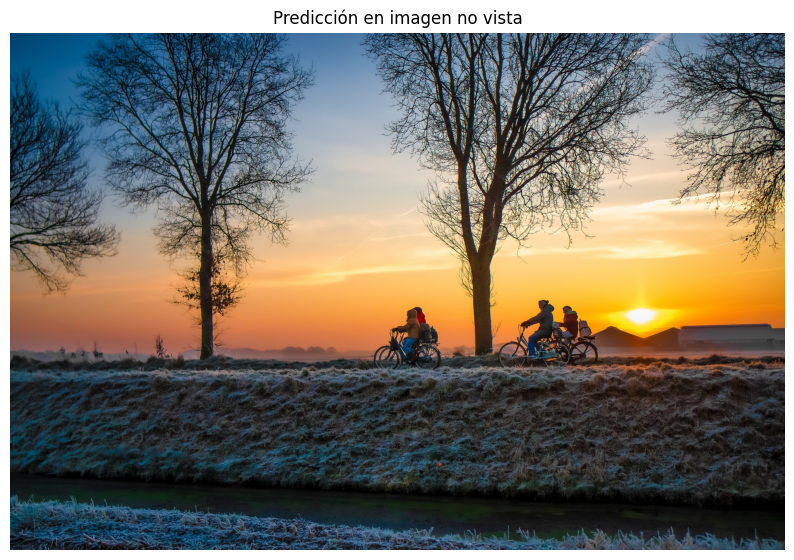

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

NEW_IMAGE = "/content/zachtleven-cycling-9394894_1920.jpg"
if os.path.exists(NEW_IMAGE):
    pred = detector.predict(source=NEW_IMAGE, conf=0.25, save=False)
    annotated = pred[0].plot()  # BGR
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[..., ::-1])
    plt.axis("off")
    plt.title("Predicción en imagen no vista")
    plt.show()
else:
    print("Actualice NEW_IMAGE con la ruta a una imagen nueva.")

Complete al menos cinco filas con casos informativos:

| Imagen/caso | Resultado esperado | Predicción observada | Tipo de error | Explicación probable |
|---|---|---|---|---|
| 1. Avenida | Detectar los vehículos visibles | Auto y bicicleta, con detecciones incorrectas | Falsos positivos y vehículos omitidos | Perspectiva elevada y objetos pequeños |
| 2. Atardecer (ultima imagen) | Detectar bicicletas | Sin detecciones | Falsos negativos | Contraluz y vehículos poco visibles |
| 3. Ciclistas urbanos | Detectar cuatro bicicletas | Dos bicicletas y una motocicleta | Confusión y omisiones | Superposición y similitud visual |
| 4. Ciclista repartidor | Detectar la bicicleta | Varias cajas de bicicleta | Detecciones superpuestas | Localización imprecisa |
| 5. Calle con motos | Detectar motocicletas estacionadas | Sin detecciones | Falsos negativos | Tamaño, perspectiva u oclusiones |
| 6. Auto clásico | Detectar un auto | Bicicleta | Clasificación incorrecta | Apariencia poco habitual del vehículo |
| 7. Auto convertible | Detectar un auto | Auto | Sin error evidente | Vehículo claramente visible |
| 8. Motos en montaña | Detectar dos motocicletas | Dos motocicletas | Sin error evidente | Siluetas reconocibles |

¿Qué patrones de error observa? ¿Qué cambio en los datos o en el entrenamiento podría ayudar? No concluya que el modelo generaliza bien basándose solo en unos pocos ejemplos.

**Respuesta:** Al evaluar el modelo con 10 imágenes nuevas, se observaron varios errores de detección, principalmente en vehículos pequeños, lejanos o parcialmente ocultos. También se presentaron confusiones entre clases, como una bicicleta identificada como motocicleta y un automóvil antiguo clasificado como bicicleta. En algunos casos el modelo generó cajas mal ajustadas o varias detecciones sobre un mismo objeto.
Sin embargo, también hubo resultados correctos, como la detección de un automóvil convertible y dos motocicletas en una carretera de montaña.

Para mejorar el rendimiento, sería conveniente ampliar el dataset con fotografías más variadas, especialmente vehículos vistos desde diferentes ángulos, objetos pequeños, escenas con poca iluminación y modelos menos comunes.

Estos resultados muestran que, aunque el modelo aprendió a reconocer ciertos vehículos, todavía presenta limitaciones al enfrentarse a situaciones diferentes a las utilizadas durante el entrenamiento.

## 7. Clasificación de imágenes

Entrene también un clasificador. En clasificación, el modelo asigna una etiqueta a la **imagen completa**; no entrega necesariamente la ubicación del objeto.

Cree en Roboflow un conjunto de clasificación con las mismas tres clases cuando sea razonable. Cada imagen debe tener una etiqueta inequívoca. Si una imagen contiene varias clases o ninguna clase dominante clara, no la fuerce a una etiqueta incorrecta: seleccione imágenes adecuadas o explique su criterio.

Exporte el conjunto en un formato compatible con Ultralytics. Compruebe la estructura y las etiquetas antes de entrenar. Habitualmente se utilizan carpetas `train`, `val` y `test`, cada una con subcarpetas por clase.

**Enlace al proyecto/dataset de clasificación:**  https://app.roboflow.com/ignacios-workspace-z5vta/clasificacion-4dmpi/1

**Imágenes por clase:**  41 imágenes de auto, 40 de bicicletas y 42 de motocicletas

**¿Cómo definió la etiqueta de cada imagen?:** Se asignó una etiqueta única a cada fotografía según el tipo de vehículo predominante. Las imágenes fueron organizadas en carpetas de autos, bicicletas y motocicletas, permitiendo que Roboflow asignara automáticamente la clase correspondiente al momento de subirlas. Se priorizaron fotografías donde la clase principal fuera claramente identificable, evitando aquellas donde diferentes tipos de vehículos tuvieran un protagonismo similar.

In [ ]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))

project = rf.workspace(
    "ignacios-workspace-z5vta"
).project("clasificacion-4dmpi")

version = project.version(1)
dataset_cls = version.download("folder")

print("Dataset de clasificación:", dataset_cls.location)
print("Ruta del dataset:", dataset_cls.location)

loading Roboflow workspace...
loading Roboflow project...
Dataset de clasificación: /content/Clasificación-1
Ruta del dataset: /content/Clasificación-1


In [ ]:
# Plantilla para clasificación con Ultralytics.
CLASSIFY_DATA = dataset_cls.location
CLASSIFY_MODEL = "yolo11n-cls.pt"

assert os.path.isdir(CLASSIFY_DATA), "Actualice CLASSIFY_DATA a la carpeta del dataset"

classifier = YOLO(CLASSIFY_MODEL)
start = time.time()
classify_results = classifier.train(
    data=CLASSIFY_DATA,
    epochs=20,
    imgsz=224,
    batch=32,
    patience=5,
    project="runs_taller2",
    name="clasificacion_experimento_1"
)
print(f"Tiempo de entrenamiento: {(time.time()-start)/60:.1f} minutos")

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Clasificación-1, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=clasificacion_experimento_1, nbs=64, nms=None, opset=None, op

### 7.1. Evaluación de clasificación

Evalúe el modelo sobre la partición de prueba reservada. Reporte e interprete, cuando estén disponibles:

- **Exactitud (*accuracy*):** proporción de predicciones correctas.
- **Precisión y exhaustividad por clase:** ayudan a identificar clases favorecidas o mal reconocidas.
- **F1-score:** combina precisión y exhaustividad.
- **Matriz de confusión:** muestra qué clases se confunden.

Si las clases están desbalanceadas, la exactitud por sí sola puede ser engañosa. Use las funciones de evaluación de la librería y explique cómo obtuvo las métricas.

In [ ]:
from ultralytics import YOLO
import os

# Plantilla: ajuste la ruta/sintaxis según la versión de Ultralytics.
classify_metrics = classifier.val(data=CLASSIFY_DATA, split="test")
print(classify_metrics)

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 3.2 GFLOPs
train: /content/Clasificación-1/train... found 86 images in 3 classes ✅ 
val: /content/Clasificación-1/valid... found 18 images in 3 classes ✅ 
test: /content/Clasificación-1/test... found 18 images in 3 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 246.4±132.7 MB/s, size: 9.7 KB)
test: Scanning /content/Clasificación-1/test... 18 images, 0 corrupt: 100% ━━━━━━━━━━━━ 18/18 3.9Kit/s 0.0s
test: New cache created: /content/Clasificación-1/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 2/2 4.3it/s 0.5s
                   all      0.944          1
Speed: 2.0ms preprocess, 11.5ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metric

¿Existe?: True


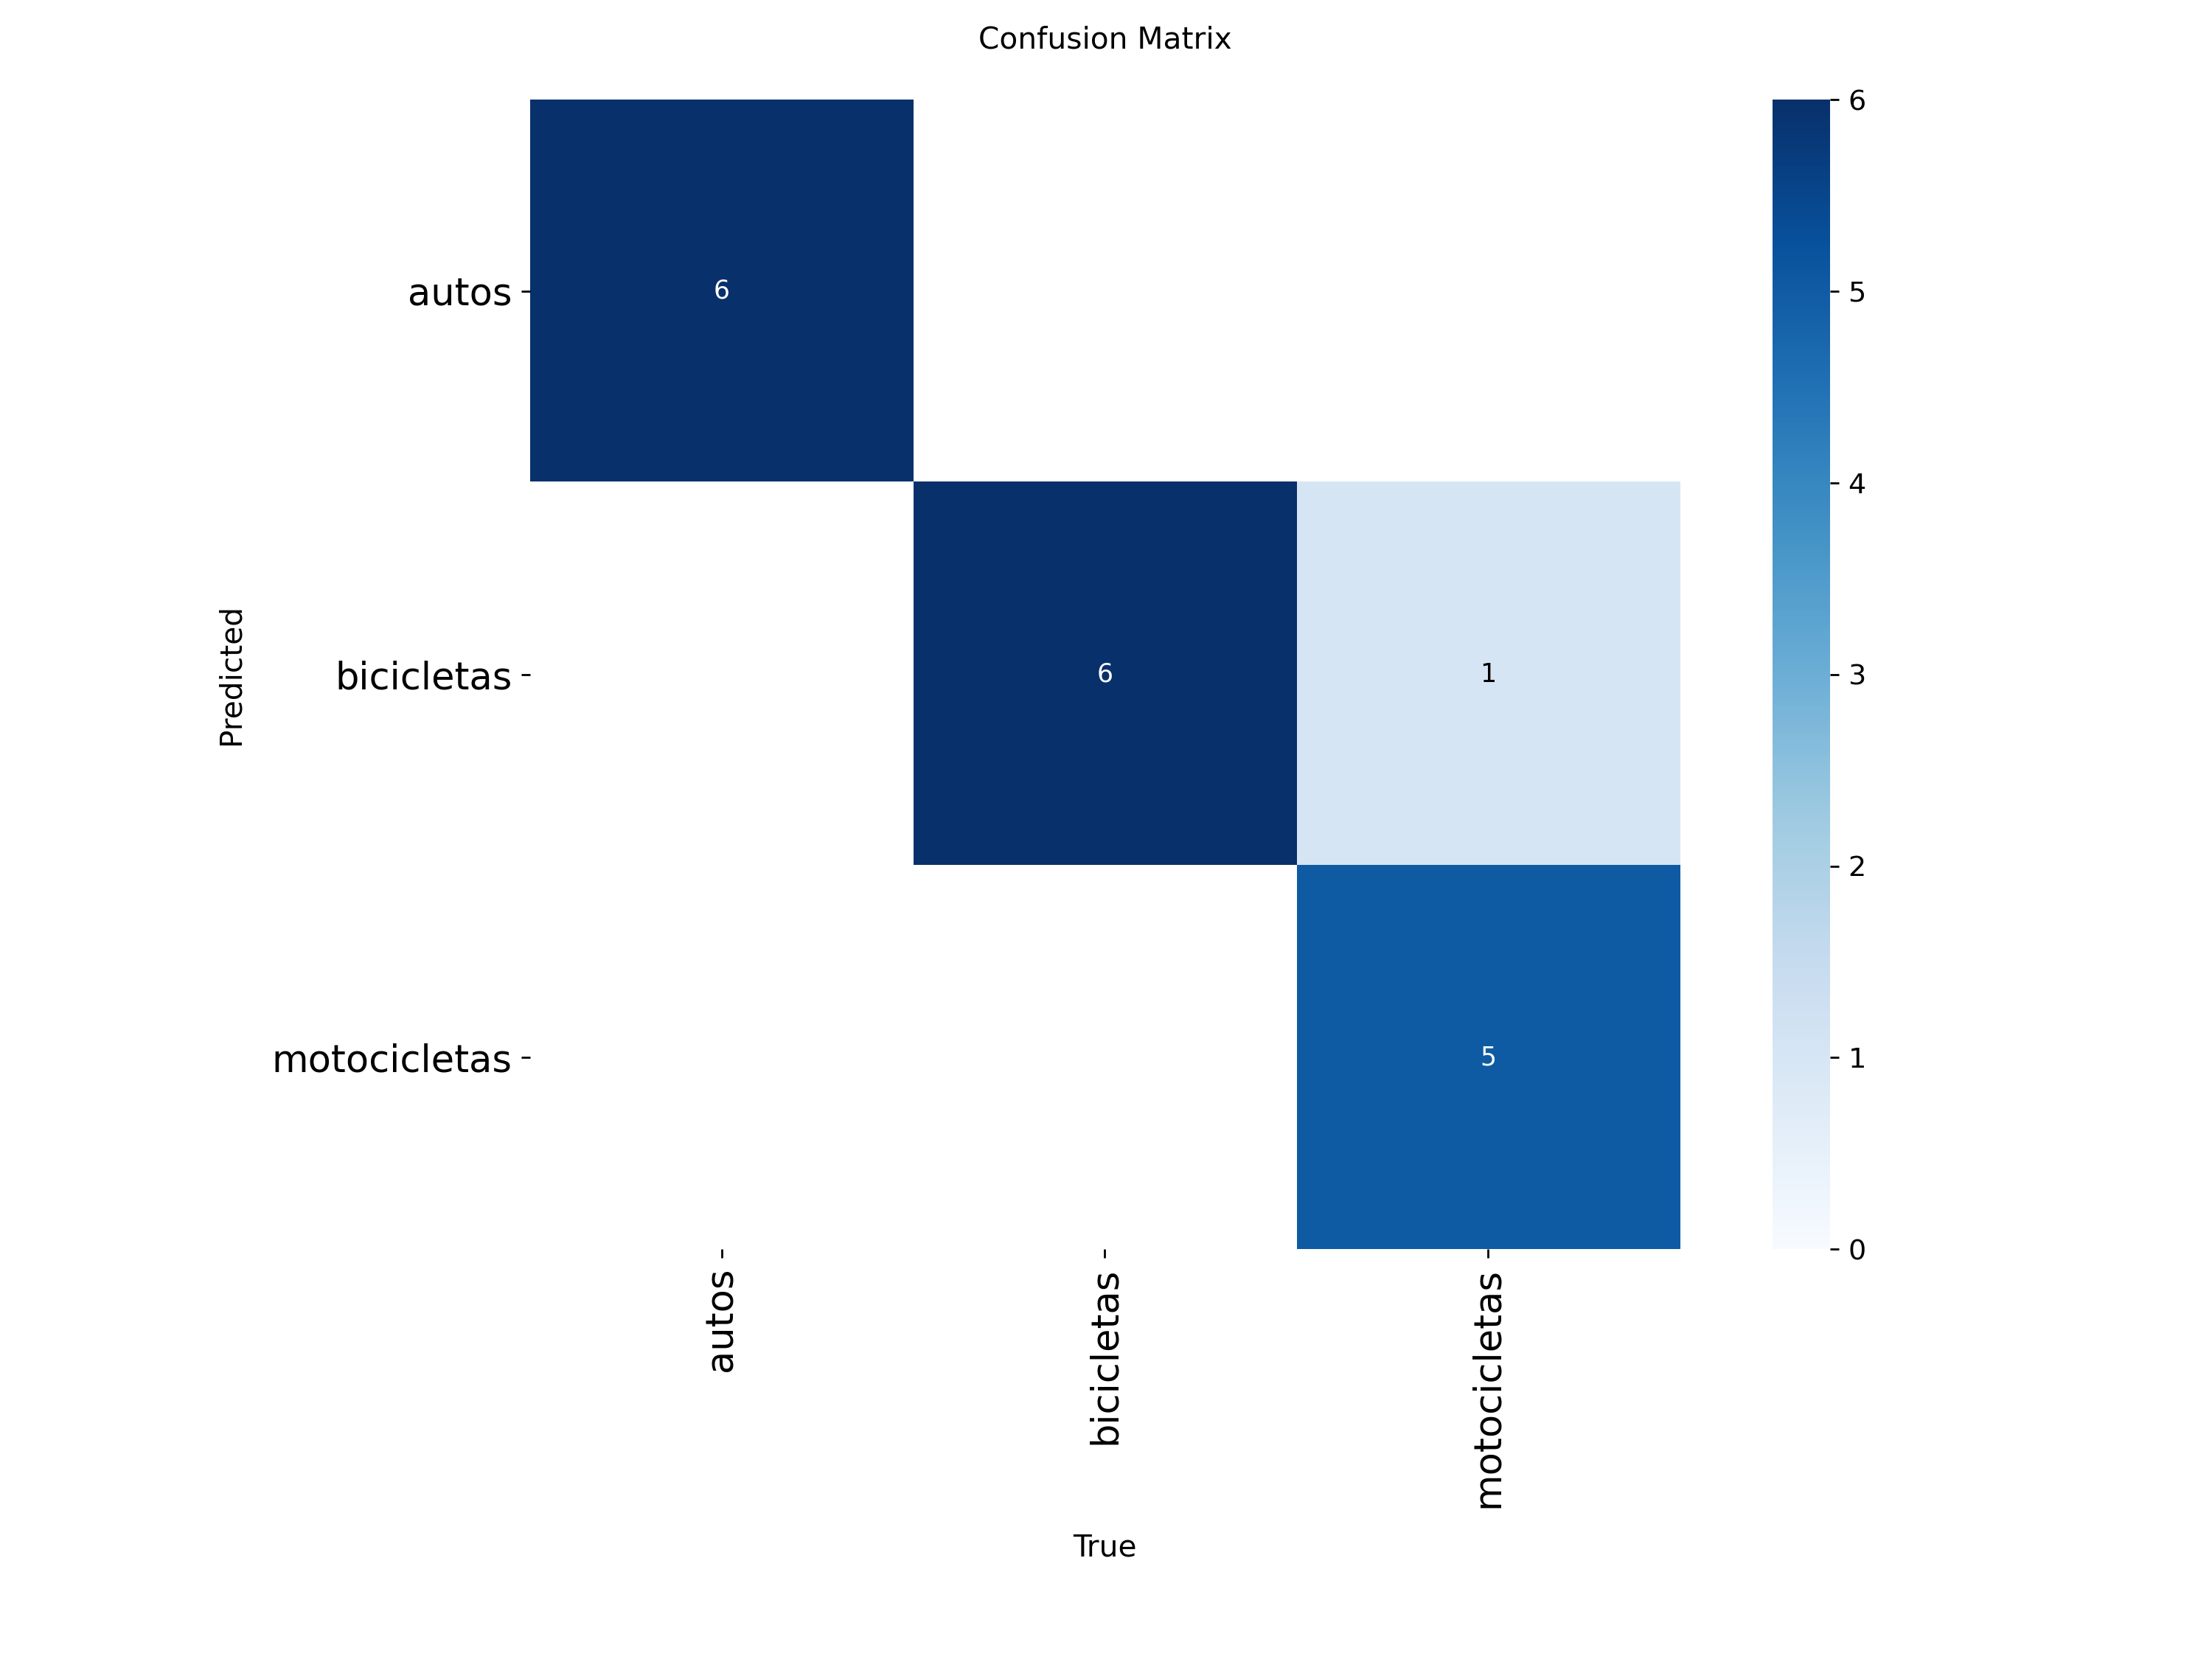

In [ ]:
#matriz de confusión
from IPython.display import Image, display
from pathlib import Path
ruta = Path(classify_metrics.save_dir) / "confusion_matrix.png"

print("¿Existe?:", ruta.exists())

if ruta.exists():
    display(Image(filename=str(ruta)))

**¿Como se obtuvieron las metricas?:**

**Respuesta:**Las métricas se obtuvieron evaluando el modelo YOLO11n-cls con las 18 imágenes del conjunto de prueba mediante la función classifier.val() de Ultralytics, que entregó directamente una exactitud Top-1 de 94,44 %.

Posteriormente, se visualizó la matriz de confusión generada por Ultralytics mediante display(). A partir de ella, se identificaron los verdaderos positivos (VP), falsos positivos (FP) y falsos negativos (FN) para calcular manualmente las siguientes métricas:

- **Precisión:** $P = \frac{VP}{VP+FP}$.
- **Recall:** $R = \frac{VP}{VP+FN}$.
- **F1-score:** $F1 = \frac{2PR}{P+R}$.


**Resultados de clasificación:**  El modelo obtuvo una exactitud Top-1 de 94,44 %, clasificando correctamente 17 de las 18 imágenes de prueba.

| Clase | Precisión | Recall | F1-score |
|---|---:|---:|---:|
| Autos | 100 % | 100 % | 100 % |
| Bicicletas | 85,71 % | 100 % | 92,31 % |
| Motocicletas | 100 % | 83,33 % | 90,91 % |




**Interpretación de la matriz de confusión:**  De las seis imágenes reales de cada clase, los seis autos y las seis bicicletas fueron clasificados correctamente. Se reconocieron cinco de las seis motocicletas; la restante se predijo como bicicleta.

¿Qué clases confunde con mayor frecuencia y por qué? ¿Cómo cambiaría su interpretación si las clases tienen cantidades muy distintas de imágenes?

**Respuesta:**La única confusión observada fue una motocicleta clasificada como bicicleta, posiblemente por similitudes visuales entre ambos vehículos. Un solo error no basta para afirmar que se trate de una confusión habitual. Si hubiera un gran desbalance entre clases, la exactitud global podría ocultar errores en las clases minoritarias; por eso convendría revisar precisión, recall y F1-score de cada clase.

---

## 8. Comparación entre detección y clasificación

| Criterio | Detección YOLO | Clasificación |
|---|---|---|
| ¿Qué predice? |Clase y ubicación de cada vehículo |Clase principal de la imagen |
| ¿Entrega ubicación? | Si, con cajas delimitadoras|No |
| Métricas utilizadas | Precisión,recall, mAP@50 y mAP@5095|Acurracy, precisión,recall y F1-score |
| Fortaleza observada | Permite detectar varios vehículos en una imagen|Obtuvo 94,44% de accuracy en prueba |
| Limitación observada | Omite vehículos pequeños y presenta confusiones entre clases| No permite localizar vehículos individuales |
| Situación en que sería preferible | Identificar vehículos en calles o intersecciones| Clasificar imágenes con un vehículo principal |

1. ¿Qué tarea resultó más adecuada para su problema y por qué?

**Respuesta:** La detección de objetos resultó más adecuada , ya que permite identificar y localizar distintos vehículos dentro de una misma imagen. Aunque la clasificación obtuvo una mayor exactitud en su evaluación, no permite identificar la ubicación de cada vehículo.

2. ¿Cuándo aporta valor conocer la ubicación del objeto?

**Respuesta:** Cuando existen varios vehículos en una misma escena, como en calles o intersecciones, ya que permite identificar individualmente cada objeto y conocer donde se encuentra.

3. ¿Qué diferencias en datos o etiquetas podrían explicar diferencias de desempeño?

**Respuesta:** En detección se utilizan cajas delimitadoras y etiquetas para cada vehículo, mientras que en clasificación se asigna una sola etiqueta por imagen. Esto hace que la detección sea una tarea más exigente, especialmente cuando los vehículos son pequeños o están parcialmente ocultos.

4. ¿Qué conclusiones no sería correcto extraer de estos resultados?

**Respuesta:** No sería correcto afirmar que la clasificación es mejor solo porque obtuvo un accuracy de 94,44%, ya que ambas tareas objetivos y métricas diferentes. Tampoco podemos asegurar que los resultados se mantengan con imágenes nuevas, debido al tamaño reducido del dataset.

## 9. Conclusiones y limitaciones

Redacte una conclusión concreta que incluya qué construyó, qué modelo/configuración funcionó mejor según sus criterios, qué evidencia lo respalda, errores relevantes, limitaciones del dataset y qué experimento haría después. Diferencie los resultados observados de las hipótesis.

**Conclusiones:** Durante el taller se construyeron dos modelos YOLO para identificar autos, bicicletas y motocicletas: uno de detección de objetos y otro de clasificación de imágenes.  

En detección, el segundo experimento, utilizando patience=20, obtuvo mejores resultados de validación que el primero, alcanzando un mAP@50 de 0,727 frente a 0,168. Sin embargo, al evaluarlo en prueba, el mAP@50 disminuyó a 0,418, lo que evidencia dificultades para generalizar a imágenes no vistas.

Por otro lado, el clasificador YOLO11n-cls obtuvo una exactitud de 94,44% en prueba, clasificando correctamente 17 de 18 imágenes. Aunque este resultado fue positivo, ambas tareas tienen objetivos y métricas diferentes, por lo que no se pueden comparar directamente sus porcentajes.

**Limitaciones:** La principal limitación fue el tamaño reducido del dataset, con aproximadamente 40 imágenes por clase, lo que limita la variedad de escenarios aprendidos por los modelos.

En detección se observaron dificultades con vehículos pequeños, objetos parcialmente ocultos y condiciones de iluminación complejas. También aparecieron falsos positivos y confusiones entre bicicletas y motocicletas.

Además, los conjuntos de prueba fueron pequeños, por lo que los resultados obtenidos no garantizan el mismo rendimiento en imágenes de otros entornos.


**Siguiente experimento propuesto:** Se propone ampliar el dataset con imágenes de vehículos en diferentes tamaños, ángulos, distancias y condiciones de iluminación, especialmente bicicletas y motocicletas.

Luego, se entrenaría nuevamente el detector YOLO11n manteniendo inicialmente la configuración del segundo experimento, apra evaluar si una amyor variedad de imágenes mejora el recall y el mAP@50 en un conjunto de pruba independiente.

Esto permitiría comprobar si las dificultades observadas se relacionan principalmente con la cantidad y diversidad de los datos de entrenamiento.

## 10. Checklist de entrega

- [X] Notebook con nombre y tres clases seleccionadas.
- [X] Dataset de al menos 120 imágenes y 40 por clase.
- [X] Proyecto Roboflow con anotaciones y versión identificable.
- [X] Fuentes de imágenes documentadas.
- [X] Revisión de anotaciones, duplicados y posibles fugas de datos (*data leakage*).
- [X] Detector YOLO entrenado y al menos dos experimentos comparables.
- [X] Métricas de detección reportadas e interpretadas.
- [X] Al menos 10 imágenes nuevas probadas y al menos cinco casos analizados.
- [X] Clasificador entrenado y evaluado.
- [X] Comparación crítica entre tareas y discusión de limitaciones.
- [X] Versiones y entorno documentados; código y resultados coherentes.
- [X] Sin claves API, tokens ni contraseñas expuestos.
- [X] README o informe con enlaces a Roboflow y a la versión exacta del dataset.
- [ ] ZIP **sin imágenes ni dataset**.
- [ ] Archivo llamado `Taller_2_Nombre_Apellido.zip`, entregado en Aula USM antes del **domingo 1 de noviembre de 2026 a las 23:59**.

### Contenido mínimo del README o informe

1. Nombre del estudiante y descripción del problema/clases.
2. Enlace al proyecto de Roboflow y a la versión del dataset.
3. Enlaces o referencias de las fuentes de imágenes.
4. Resumen de experimentos y resultados principales.
5. Entorno utilizado (Colab/local) y observaciones para reproducir.
6. Limitaciones importantes para ejecutar el notebook.

**Recuerde:** suba el ZIP a Aula USM. Las imágenes y el dataset permanecen en Roboflow y repo externo como OneDrive; no los adjunte a Aula.